In [1]:
!pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import mysql.connector

# 1. Configuration de la connexion
db_config = {
    'host': 'localhost',
    'user': 'root', 
    'password': 'Password21',
    'database': 'classicmodels'
}

# 2. Connexion à la base
try:
    conn = mysql.connector.connect(**db_config)
    print("✅ Connexion réussie à MySQL !")
    
    # 3. Petit test pour voir si on récupère des données
    df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)
    display(df_test)
    
except Exception as e:
    print(f"❌ Erreur de connexion : {e}")

✅ Connexion réussie à MySQL !


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/732113366.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)


,customerName,city,country
0,Atelier graphique,Nantes,France
1,Signal Gift Stores,Las Vegas,USA
2,"Australian Collectors, Co.",Melbourne,Australia
3,La Rochelle Gifts,Nantes,France
4,Baane Mini Imports,Stavern,Norway


In [3]:
import sys
!{sys.executable} -m pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1273171162.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_status = pd.read_sql(query_status, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1273171162.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_status, x='Nombre', y='status', palette='muted')


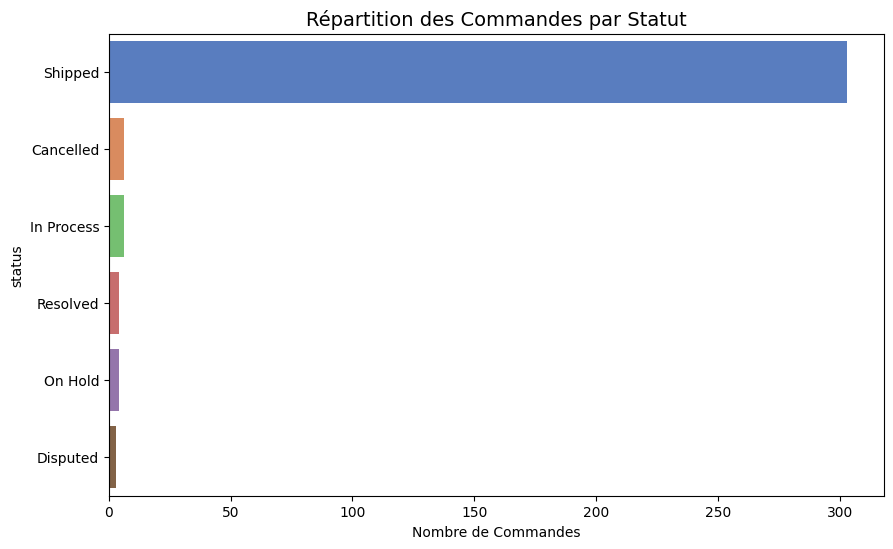

In [4]:
#-- --------------------------------------------
# 1. PARTIE 1: EXPLORATION VISUELLE
#-- --------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
# --- 1.1 DISTRIBUTION DES STATUTS DE COMMANDE ---

# --- AJOUTE CES IMPORTS ICI ---
import matplotlib.pyplot as plt
import seaborn as sns
# ------------------------------

query_status = """
SELECT status, COUNT(*) as Nombre
FROM orders
GROUP BY status
ORDER BY Nombre DESC;
"""
df_status = pd.read_sql(query_status, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_status, x='Nombre', y='status', palette='muted')
plt.title('Répartition des Commandes par Statut', fontsize=14)
plt.xlabel('Nombre de Commandes')

# Sauvegarde
plt.savefig("../visualizations/01_01_order_status.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1552734008.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_stock = pd.read_sql(query_stock, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1552734008.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_stock, x='Nombre_References', y='productLine', palette='Blues_d')


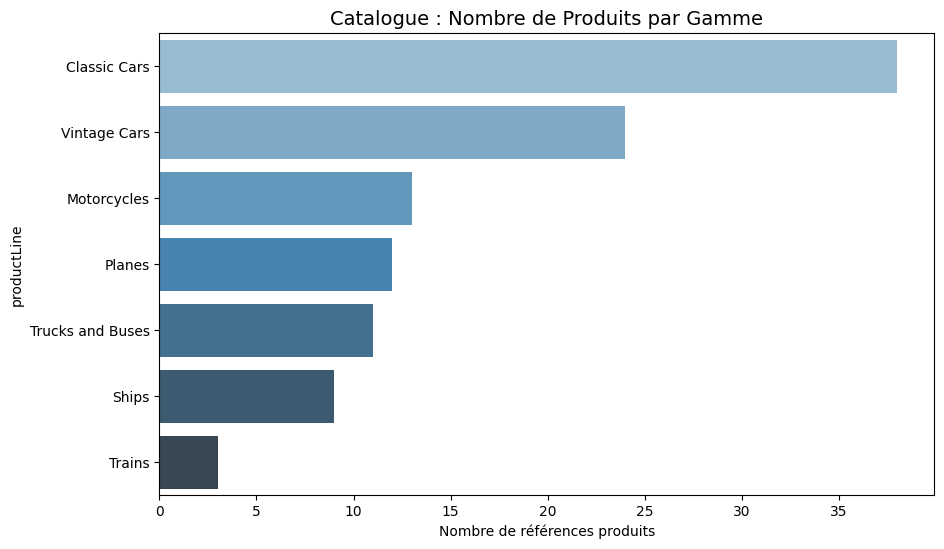

In [5]:
# --- 1.2 INVENTAIRE (Nombre de références par Gamme) ---

query_stock = """
SELECT productLine, COUNT(*) as Nombre_References
FROM products
GROUP BY productLine
ORDER BY Nombre_References DESC;
"""
df_stock = pd.read_sql(query_stock, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_stock, x='Nombre_References', y='productLine', palette='Blues_d')
plt.title('Catalogue : Nombre de Produits par Gamme', fontsize=14)
plt.xlabel('Nombre de références produits')

# Sauvegarde
plt.savefig("../visualizations/01_02_product_count.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1645286564.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_credit = pd.read_sql(query_credit, conn)


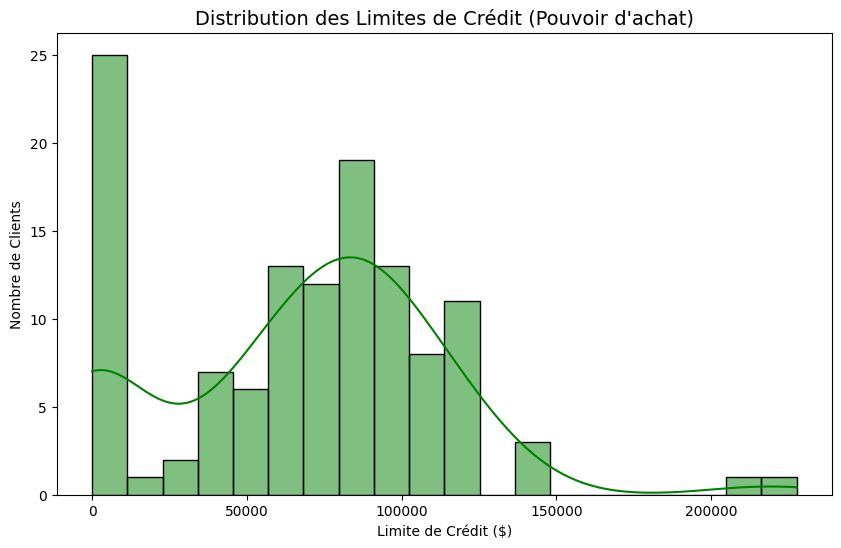

In [6]:
# --- 1.3 DISTRIBUTION DES LIMITES DE CRÉDIT CLIENTS ---

query_credit = "SELECT creditLimit FROM customers;"
df_credit = pd.read_sql(query_credit, conn)

plt.figure(figsize=(10, 6))
sns.histplot(df_credit['creditLimit'], bins=20, kde=True, color='green')
plt.title('Distribution des Limites de Crédit (Pouvoir d\'achat)', fontsize=14)
plt.xlabel('Limite de Crédit ($)')
plt.ylabel('Nombre de Clients')

# Sauvegarde
plt.savefig("../visualizations/01_03_credit_distribution.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/3986749514.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_offices = pd.read_sql(query_offices, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/3986749514.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_offices, x='Nb_Employes', y='Ville', palette='viridis')


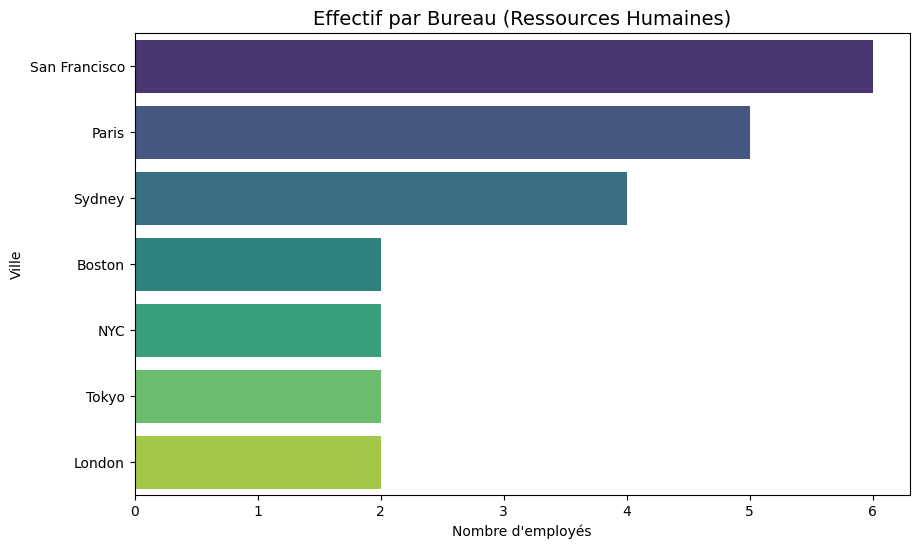

In [7]:
# --- 1.4 RÉPARTITION RH : Employés par Bureau ---

query_offices = """
SELECT o.city as Ville, COUNT(e.employeeNumber) as Nb_Employes
FROM offices o
JOIN employees e ON o.officeCode = e.officeCode
GROUP BY Ville
ORDER BY Nb_Employes DESC;
"""
df_offices = pd.read_sql(query_offices, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_offices, x='Nb_Employes', y='Ville', palette='viridis')
plt.title('Effectif par Bureau (Ressources Humaines)', fontsize=14)
plt.xlabel('Nombre d\'employés')

# Sauvegarde
plt.savefig("../visualizations/01_04_employees_per_office.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/736679819.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pay_stats = pd.read_sql(query_pay_stats, conn)


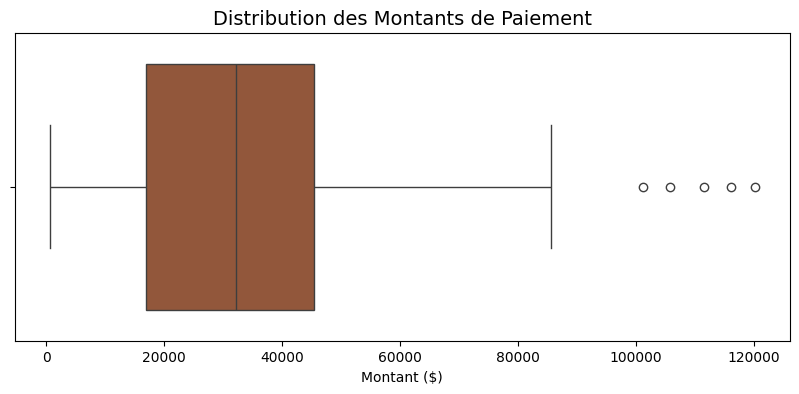

In [8]:
# --- 1.5 DISTRIBUTION DES PAIEMENTS (Boxplot) ---

query_pay_stats = "SELECT amount FROM payments;"
df_pay_stats = pd.read_sql(query_pay_stats, conn)

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_pay_stats['amount'], color='sienna')
plt.title('Distribution des Montants de Paiement', fontsize=14)
plt.xlabel('Montant ($)')

# Sauvegarde
plt.savefig("../visualizations/01_05_payments_distribution.png", bbox_inches='tight')
plt.show()

In [9]:
#-- ---------------------------------------------
# PARTIE 2:REQUÊTES SQL AVANCÉES(PIVOT)
#-- ---------------------------------------------

# --- 5.1 SEGMENTATION AVANCÉE (JOINTURE 6 TABLES) ---
# On identifie les clients VIP, leur gamme préférée et leur total d'achats

query_complex_vip = """
SELECT 
    c.customerName,
    pl.productLine as Gamme_Preferee,
    COUNT(DISTINCT o.orderNumber) as Nb_Commandes,
    SUM(od.quantityOrdered * od.priceEach) as Total_Achat,
    MAX(p.paymentDate) as Dernier_Paiement
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
JOIN products pr ON od.productCode = pr.productCode
JOIN productlines pl ON pr.productLine = pl.productLine
JOIN payments p ON c.customerNumber = p.customerNumber
WHERE o.status = 'Shipped'
GROUP BY c.customerName, pl.productLine
HAVING Total_Achat > 5000
ORDER BY Total_Achat DESC
LIMIT 10;
"""
df_vip_complex = pd.read_sql(query_complex_vip, conn)

print("✅ Analyse VIP complexe chargée !")
display(df_vip_complex)

✅ Analyse VIP complexe chargée !


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2959568540.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_vip_complex = pd.read_sql(query_complex_vip, conn)


,customerName,Gamme_Preferee,Nb_Commandes,Total_Achat,Dernier_Paiement
0,Euro+ Shopping Channel,Classic Cars,16,4706593.06,2005-05-19
1,Mini Gifts Distributors Ltd.,Classic Cars,14,2358740.61,2005-04-16
2,Euro+ Shopping Channel,Vintage Cars,12,1413541.87,2005-05-19
3,Mini Gifts Distributors Ltd.,Vintage Cars,12,1236330.18,2005-04-16
4,Euro+ Shopping Channel,Trucks and Buses,7,1103967.15,2005-05-19
5,Mini Gifts Distributors Ltd.,Trucks and Buses,9,1025743.32,2005-04-16
6,Muscle Machine Inc,Classic Cars,4,536240.52,2004-12-14
7,Euro+ Shopping Channel,Ships,3,522809.69,2005-05-19
8,Euro+ Shopping Channel,Trains,6,364585.65,2005-05-19
9,"Down Under Souveniers, Inc",Classic Cars,4,348409.32,2005-05-23


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1614346879.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_retention = pd.read_sql(query_retention, conn)


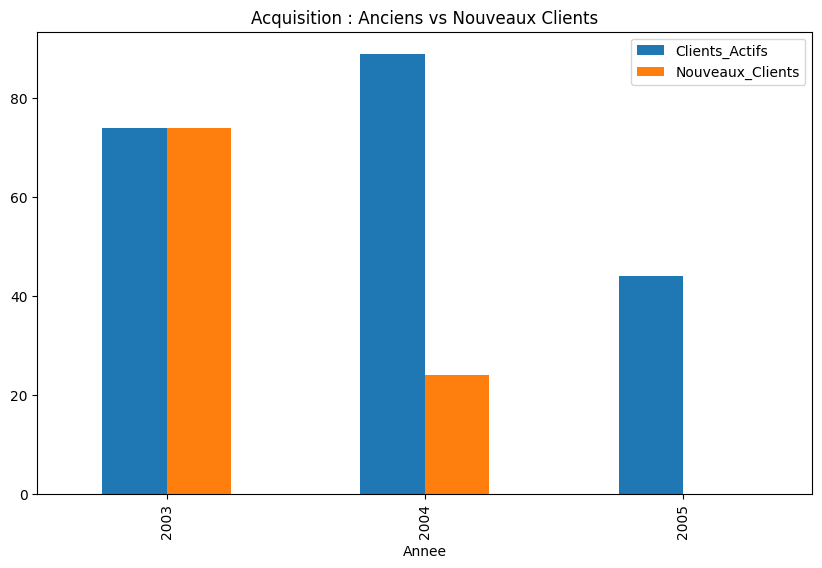

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
# --- 5.2 ANALYSE RÉTENTION (SOUS-REQUÊTE) ---
query_retention = """
SELECT 
    T_Global.Annee,
    T_Global.Clients_Actifs,
    IFNULL(T_New.Nouveaux_Clients, 0) as Nouveaux_Clients
FROM
    (SELECT YEAR(orderDate) as Annee, COUNT(DISTINCT customerNumber) as Clients_Actifs 
     FROM orders GROUP BY Annee) as T_Global
LEFT JOIN
    (SELECT YEAR(min_date) as Annee, COUNT(*) as Nouveaux_Clients
     FROM (SELECT customerNumber, MIN(orderDate) as min_date FROM orders GROUP BY customerNumber) as sub
     GROUP BY Annee) as T_New
ON T_Global.Annee = T_New.Annee
ORDER BY T_Global.Annee;
"""
df_retention = pd.read_sql(query_retention, conn)

df_retention.set_index('Annee')[['Clients_Actifs', 'Nouveaux_Clients']].plot(kind='bar', figsize=(10, 6))
plt.title('Acquisition : Anciens vs Nouveaux Clients')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2625943683.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pivot_data = pd.read_sql(query_pivot, conn)


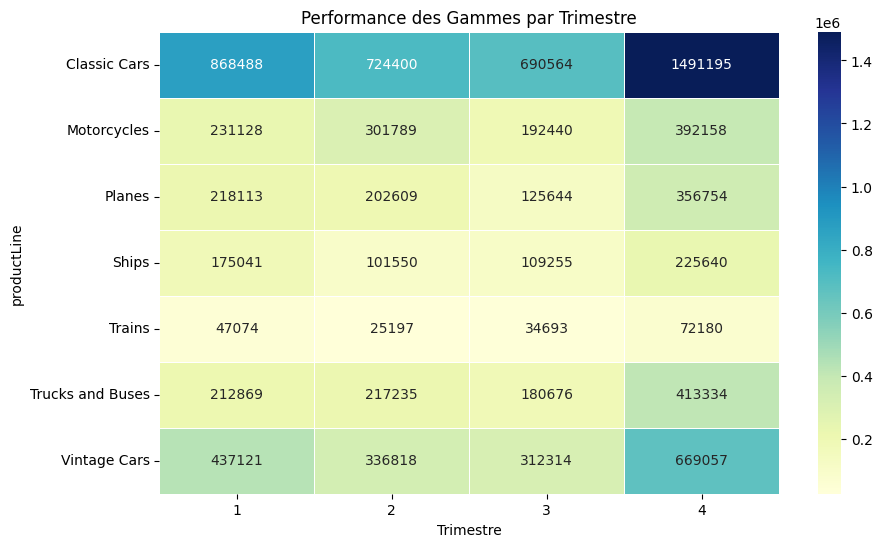

In [11]:
# --- 5.3 TABLEAU PIVOT (HEATMAP) ---

query_pivot = """
SELECT 
    p.productLine,
    QUARTER(o.orderDate) as Trimestre,
    SUM(od.quantityOrdered * od.priceEach) as CA
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
JOIN products p ON od.productCode = p.productCode
WHERE o.status != 'Cancelled'
GROUP BY p.productLine, Trimestre;
"""
df_pivot_data = pd.read_sql(query_pivot, conn)

# On utilise la puissance de Python pour créer le pivot
pivot_table = df_pivot_data.pivot_table(
    index='productLine', 
    columns='Trimestre', 
    values='CA', 
    aggfunc='sum'
).fillna(0)

# Affichage en Heatmap (Carte de chaleur)
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5)
plt.title('Performance des Gammes par Trimestre')

# Sauvegarde
plt.savefig("../visualizations/05_pivot_heatmap.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2841921005.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sales = pd.read_sql(query_sales, conn)


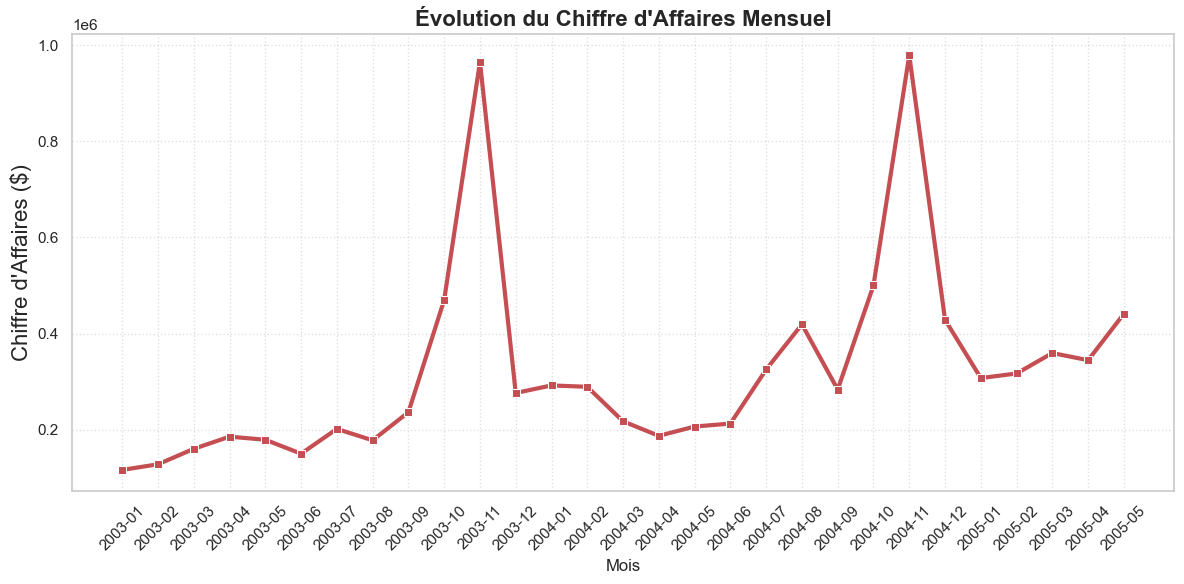

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
#-- -------------------------------------------------
# PARTIE 3: VISUALISATIONS PYTHON
#-- -------------------------------------------------
# 1. La Requête SQL (On récupère le CA par mois)
query_sales = """
SELECT 
    DATE_FORMAT(o.orderDate, '%Y-%m') as Mois,
    SUM(od.quantityOrdered * od.priceEach) as Chiffre_Affaires
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Mois
ORDER BY Mois;
"""

# 2. je charge les données dans un DataFrame
df_sales = pd.read_sql(query_sales, conn)

# 3. je dessine le graphique
plt.figure(figsize=(12, 6)) # Taille de l'image
sns.set_theme(style="whitegrid") 

# Création de la courbe
sns.lineplot(data=df_sales, x='Mois', y='Chiffre_Affaires', marker='s', color='r', linewidth=3)

# 4. Mise en forme
plt.title('Évolution du Chiffre d\'Affaires Mensuel', fontsize=16, fontweight='bold')
plt.xlabel('Mois', fontsize=12)
plt.ylabel('Chiffre d\'Affaires ($)', fontsize=16)
plt.xticks(rotation=45) # On penche les dates pour qu'elles soient lisibles
plt.grid(True, linestyle=':', alpha=0.6)

# Affichage
plt.tight_layout()
plt.savefig("../visualizations/Evolution_CA_Mensuel.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/3099312923.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_geo = pd.read_sql(query_geo, conn)


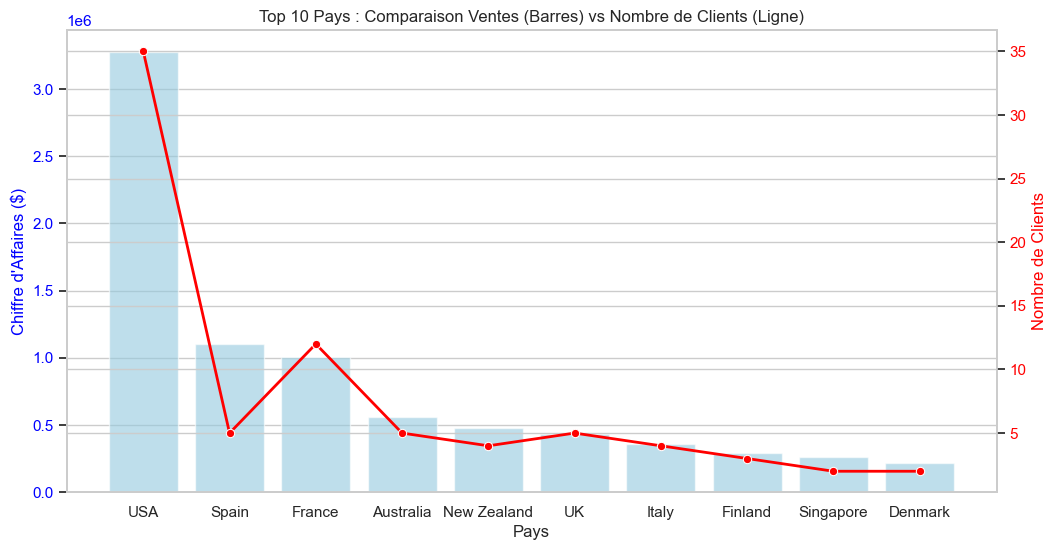

In [20]:
# --VISUALISATION 3: ANALYSE GÉOGRAPHIQUE COMPLÈTE (CLIENTS vs VENTES) ---
# Objectif : Voir si les pays avec le plus de clients sont ceux qui rapportent le plus.

query_geo = """
SELECT 
    c.country as Pays,
    COUNT(DISTINCT c.customerNumber) as Nb_Clients,
    SUM(od.quantityOrdered * od.priceEach) as Ventes_Totales
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
GROUP BY Pays
ORDER BY Ventes_Totales DESC
LIMIT 10;
"""
df_geo = pd.read_sql(query_geo, conn)

# Création d'un graphique à deux axes (Barres pour Ventes, Ligne pour Clients)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Axe 1 : Les Ventes (Barres Bleues)
sns.barplot(data=df_geo, x='Pays', y='Ventes_Totales', color='skyblue', ax=ax1, alpha=0.6)
ax1.set_ylabel('Chiffre d\'Affaires ($)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Axe 2 : Les Clients (Ligne Rouge)
ax2 = ax1.twinx()
sns.lineplot(data=df_geo, x='Pays', y='Nb_Clients', color='red', marker='o', linewidth=2, ax=ax2)
ax2.set_ylabel('Nombre de Clients', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Top 10 Pays : Comparaison Ventes (Barres) vs Nombre de Clients (Ligne)')
plt.savefig("../visualizations/Top 10 Pays : Comparaison Ventes (Barres) vs Nombre de clients (Ligne).png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2800336619.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_products = pd.read_sql(query_products, conn)


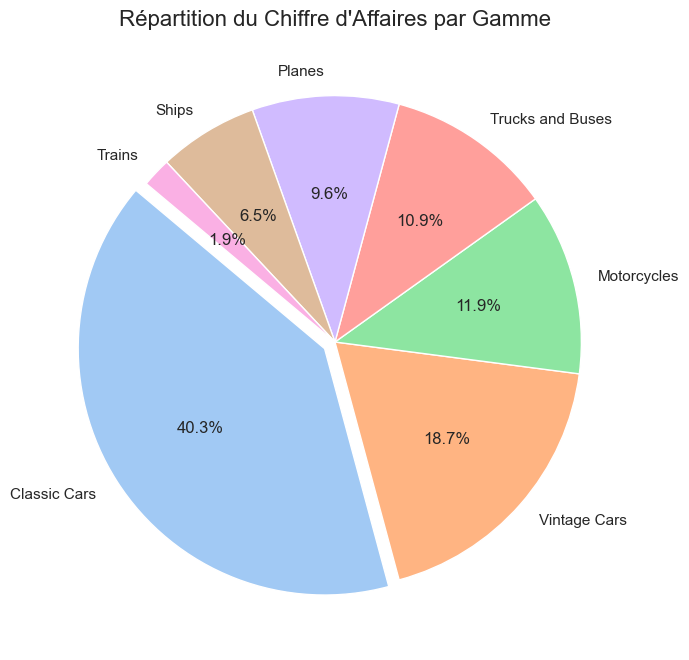

In [21]:
# 1. La Requête SQL (Total ventes par Gamme)
query_products = """
SELECT 
    p.productLine,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productLine
ORDER BY Total_Ventes DESC;
"""

# 2. Chargement
df_products = pd.read_sql(query_products, conn)

# 3. Le Graphique (Pie Chart)
plt.figure(figsize=(8, 8))

# je définit des couleurs pastels 
colors = sns.color_palette('pastel')[0:7]

plt.pie(df_products['Total_Ventes'], 
        labels=df_products['productLine'], 
        autopct='%1.1f%%', # Affiche les pourcentages
        startangle=140, 
        colors=colors,
        explode=(0.05, 0, 0, 0, 0, 0, 0)) # "Détache" la première part (Voitures)

plt.title('Répartition du Chiffre d\'Affaires par Gamme', fontsize=16)
plt.savefig("../visualizations/Répartition_du Chiffre_d\'Affaires_Mensuel.png", bbox_inches='tight')
plt.show()

###  Analyse de la répartition <span style="color:purple">des ventes</span>

On observe une forte dépendance envers une seule catégorie :
* Les <b style="color:blue">**Classic Cars</b>**40.3%** du chiffre d'affaires total.
* Les <b style="color:red">**Vintage Cars</b>**arrivent en seconde position avec environ 20%.

**Conclusion :** L'entreprise est très exposée au marché de l'automobile de collection (plus de 60% des revenus cumulés). Une diversification vers les *Motos* ou les *Avions* pourrait réduire ce risque.
**Remarque :** Si demain la mode des voitures classiques passe, l'entreprise perd 40% de son chiffre d'affaires.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/534840411.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_countries = pd.read_sql(query_countries, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/534840411.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')


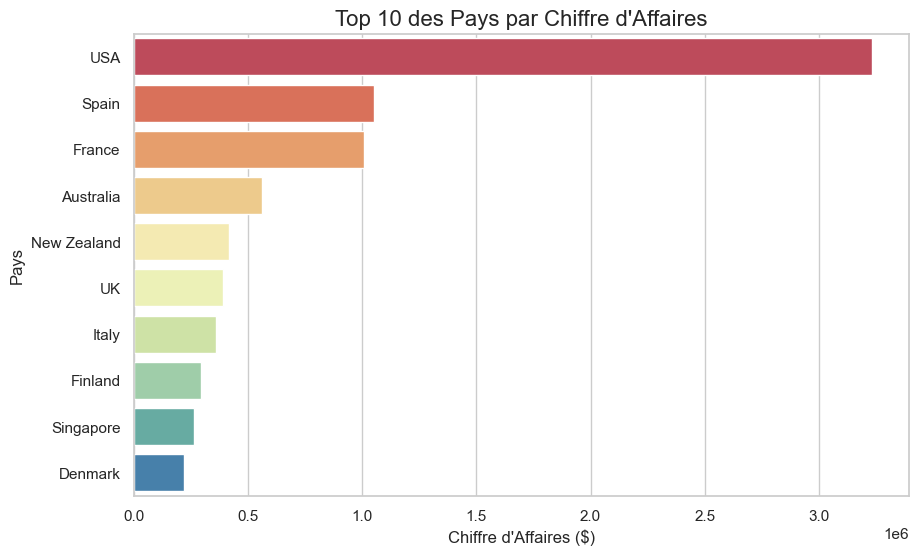

In [14]:
# 1. La Requête (Top 10 Pays par Chiffre d'Affaires)
query_countries = """
SELECT 
    c.country as Pays,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Pays
ORDER BY Total_Ventes DESC
LIMIT 10;
"""

# 2. Chargement
df_countries = pd.read_sql(query_countries, conn)

# 3. Le Graphique
plt.figure(figsize=(10, 6))

# j'utilise une palette de couleurs "Spectral"
sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')

plt.title('Top 10 des Pays par Chiffre d\'Affaires', fontsize=16)
plt.xlabel('Chiffre d\'Affaires ($)')
plt.ylabel('Pays')
plt.savefig("../visualizations/Top 10 des Pays Par Chiffre d\'Affaires.png", bbox_inches='tight')
plt.show()

###  Analyse Géographique : La domination Américaine

Ce graphique met en évidence une **disparité géographique majeure** dans notre chiffre d'affaires :

1.  **Le Géant Américain :**
    * Les **États-Unis** dominent écrasant le classement.
    * À eux seuls, ils génèrent plus de chiffre d'affaires que les **3 pays suivants réunis** (Espagne, France, Australie).
    * C'est notre "vache à lait" (Cash Cow), mais c'est aussi un **risque** : si le marché US s'effondre, l'entreprise est en danger.

2.  **Le Pôle Européen :**
    * L'Europe est notre second moteur de croissance, tiré par le trio **<span style="color:red">Espagne</span>**, **<span style="color:blue">France</span>** et **Royaume-Uni**.
    * Ces marchés montrent un fort potentiel mais restent loin derrière les USA.

**Recommandation  :**
Il est crucial de **sécuriser** le marché américain tout en **investissant massivement en Europe** pour rééquilibrer les revenus. Une campagne marketing ciblée en *France* et en *Espagne* pourrait offrir le meilleur retour sur investissement (ROI).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/4134307053.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_products = pd.read_sql(query_top_products, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/4134307053.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')


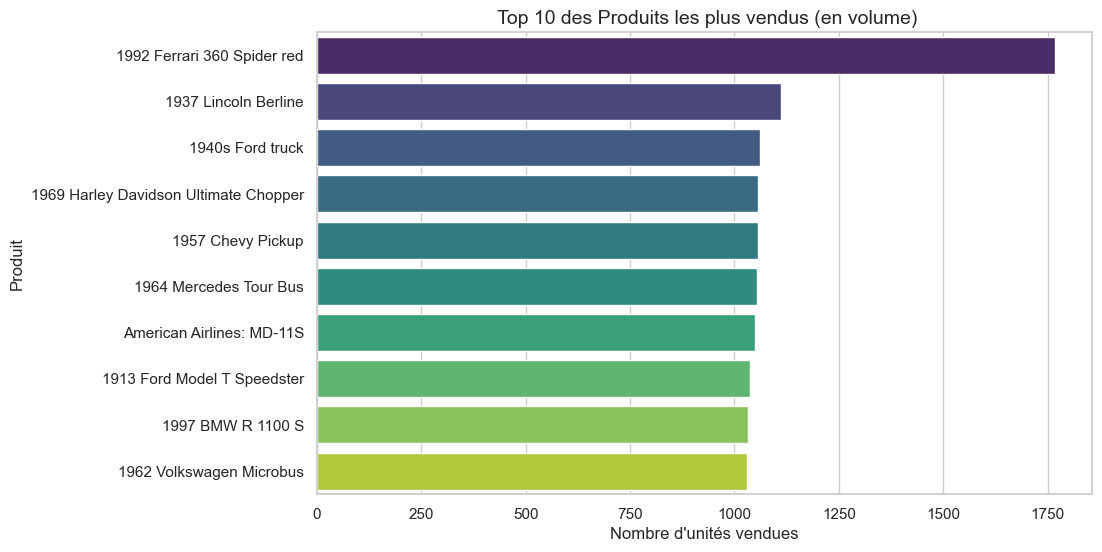

In [15]:
# --- VISUALISATION 4 : TOP 10 PRODUITS ---

# 1. Requête SQL
query_top_products = """
SELECT 
    p.productName, 
    SUM(od.quantityOrdered) as Total_Vendus
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productName
ORDER BY Total_Vendus DESC
LIMIT 10;
"""

# 2. Chargement
df_top_products = pd.read_sql(query_top_products, conn)

# 3. Graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')

plt.title(' Top 10 des Produits les plus vendus (en volume)', fontsize=14)
plt.xlabel('Nombre d\'unités vendues')
plt.ylabel('Produit')
plt.savefig("../visualizations/Top 10 des Produits les plus vendus (en volume).png", bbox_inches='tight')
plt.show()

### Analyse des Best-Sellers

**Observation :**
Ce graphique identifie nos "produits stars" en termes de volume de vente.
* La **Ferrari 1992** (ou le modèle en tête) domine largement les commandes.
* On remarque que les modèles réduits de voitures anciennes (*Vintage Cars*) sont les plus populaires.

**Stratégie :**
Ces 10 produits sont essentiels pour attirer les clients. Il faut s'assurer qu'ils soient :
1.  Toujours mis en avant sur la page d'accueil du site.
2.  Jamais en rupture de stock (priorité logistique).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1008476175.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_stock = pd.read_sql(query_stock, conn)


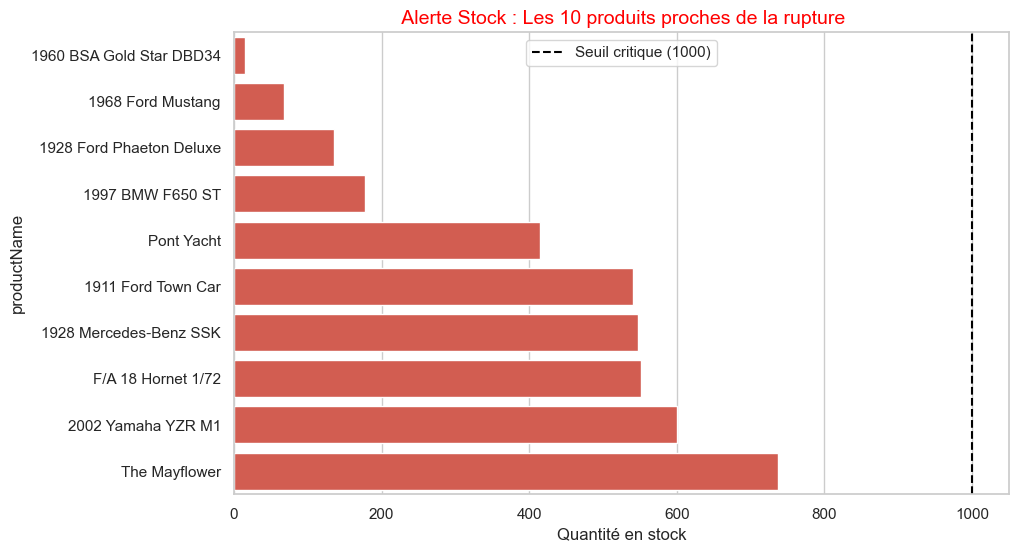

In [16]:
# --- VISUALISATION 5 : ÉTAT DES STOCKS CRITIQUES ---

# 1. Requête (Les 10 produits avec le stock le plus bas)
query_stock = """
SELECT productName, quantityInStock, productLine 
FROM products 
ORDER BY quantityInStock ASC 
LIMIT 10;
"""

df_stock = pd.read_sql(query_stock, conn)

# 2. Graphique
plt.figure(figsize=(10, 6))
# On utilise une couleur rouge pour signaler l'urgence
sns.barplot(data=df_stock, x='quantityInStock', y='productName', color='#e74c3c')

plt.title(' Alerte Stock : Les 10 produits proches de la rupture', fontsize=14, color='red')
plt.xlabel('Quantité en stock')
plt.axvline(x=1000, color='black', linestyle='--', label='Seuil critique (1000)') # Ligne de seuil
plt.legend()
plt.savefig("../visualizations/Alerte Stock: Les 10 produits proches de la rupture.png", bbox_inches='tight')
plt.show()

###  Alerte Logistique : Risque de Rupture

**Diagnostic Critique :**
Le graphique met en évidence 10 produits dont le stock est dangereusement bas (souvent sous les 1000 unités ou proche de 0).
* Si ces produits tombent à 0, nous perdons des ventes directes (Manque à gagner).
* Certains produits très demandés risquent la rupture imminente.

**Action Requise :**
Déclencher un **réapprovisionnement immédiat** auprès des fournisseurs pour ces 10 références afin d'éviter le "Stock-out" avant la fin du trimestre.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2642706573.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pareto = pd.read_sql(query_pareto, conn)


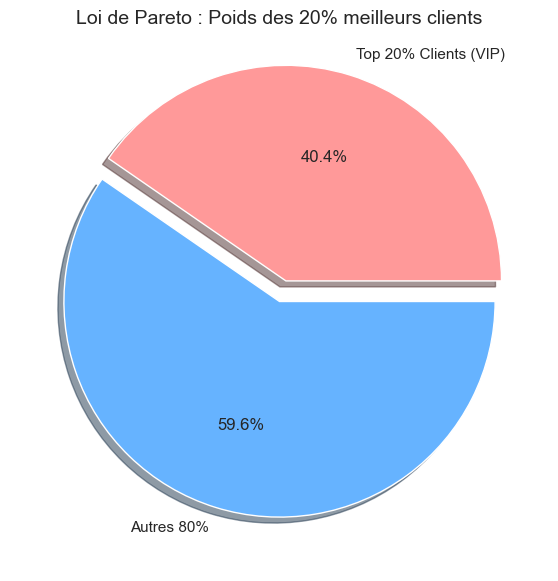

In [24]:
# --- VISUALISATION 6 : PARETO DES CLIENTS ---

# 1. On récupère le CA par client
query_pareto = """
SELECT 
    c.customerName,
    SUM(od.quantityOrdered * od.priceEach) as CA
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY c.customerName
ORDER BY CA DESC;
"""

df_pareto = pd.read_sql(query_pareto, conn)

# 2. Calculs Python (On divise en "Top 20%" et "Autres")
top_20_count = int(len(df_pareto) * 0.2)
top_clients = df_pareto.head(top_20_count)['CA'].sum()
other_clients = df_pareto.iloc[top_20_count:]['CA'].sum()

# 3. Graphique Camembert Comparatif
plt.figure(figsize=(7, 7))
plt.pie([top_clients, other_clients], 
        labels=['Top 20% Clients (VIP)', 'Autres 80%'], 
        autopct='%1.1f%%', 
        colors=['#ff9999', '#66b3ff'],
        explode=(0.1, 0), # On détache la part VIP
        shadow=True)

plt.title('Loi de Pareto : Poids des 20% meilleurs clients', fontsize=14)
plt.savefig("../visualizations/Loi de Pareto : Poids des 20% meilleurs clients.png", bbox_inches='tight')
plt.show()

###  Analyse de Pareto (Loi des 80/20)

**Constat Frappant :**
Nous observons une forte concentration du chiffre d'affaires :
* Une minorité de clients (nos **VIP**) génère une part disproportionnée des revenus.
* C'est la confirmation classique de la loi de Pareto : environ **20% des clients rapportent 80% du CA** (ou s'en approchent).

**Recommandation CRM :**
* **Pour les VIP (Partie pink) :** Il faut absolument les fidéliser (Service client dédié, offres exclusives, cadeaux) car le départ d'un seul de ces clients impacterait lourdement le CA.
* **Pour les Autres (Partie blue) :** Mettre en place des campagnes d'emailing automatisées pour essayer de les faire passer dans la catégorie supérieure.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2846009839.py:20: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_rfm = pd.read_sql(query_rfm, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2846009839.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_rfm, x='Segment', palette='Spectral', order=['VIP', 'Fidèle / Régulier', 'À Risque', 'Perdu'])


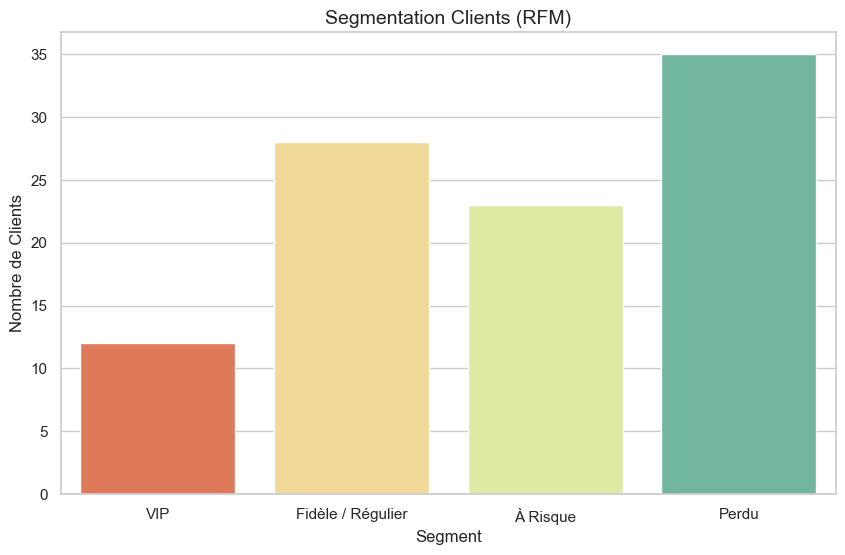

In [41]:
#-- -------------------------------------------------
# PARTIE 4: ANALYSE PYTHON AVANCÉES
#-- -------------------------------------------------

# --- 4.1 ANALYSE RFM (Recency, Frequency, Monetary) ---

# 1. Préparation des données
query_rfm = """
SELECT 
    c.customerNumber,
    MAX(o.orderDate) as last_order_date,
    COUNT(DISTINCT o.orderNumber) as frequency,
    SUM(od.quantityOrdered * od.priceEach) as monetary
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY c.customerNumber;
"""
df_rfm = pd.read_sql(query_rfm, conn)

# --- CORRECTION ---
# On convertit la colonne en vraie date pour éviter l'erreur "AttributeError"
df_rfm['last_order_date'] = pd.to_datetime(df_rfm['last_order_date'])
# -------------------------------

# 2. Calcul de la Récence (Nombre de jours depuis la dernière commande)
# On prend la date la plus récente de la base comme "Aujourd'hui" pour ne pas fausser les calculs
current_date = df_rfm['last_order_date'].max()
df_rfm['recency'] = (current_date - df_rfm['last_order_date']).dt.days

# 3. Création des scores (1 à 4) avec qcut (Quartiles)
# Récence : On veut un chiffre petit (donc on inverse les labels : 4 est le meilleur)
df_rfm['R'] = pd.qcut(df_rfm['recency'], 4, labels=[4, 3, 2, 1])
df_rfm['F'] = pd.qcut(df_rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4])
df_rfm['M'] = pd.qcut(df_rfm['monetary'], 4, labels=[1, 2, 3, 4])

# 4. Création du Score RFM Global
df_rfm['RFM_Score'] = df_rfm['R'].astype(str) + df_rfm['F'].astype(str) + df_rfm['M'].astype(str)

# 5. Segmentation (Logique Métier simplifiée)
def segment_customer(row):
    r, f, m = int(row['R']), int(row['F']), int(row['M'])
    if r >= 4 and f >= 4 and m >= 4:
        return 'VIP'
    elif r >= 3 and f >= 3:
        return 'Fidèle / Régulier'
    elif r <= 2 and r > 1:
        return 'À Risque'
    else:
        return 'Perdu'

df_rfm['Segment'] = df_rfm.apply(segment_customer, axis=1)

# 6. Visualisation
plt.figure(figsize=(10, 6))
sns.countplot(data=df_rfm, x='Segment', palette='Spectral', order=['VIP', 'Fidèle / Régulier', 'À Risque', 'Perdu'])
plt.title('Segmentation Clients (RFM)', fontsize=14)
plt.ylabel('Nombre de Clients')
plt.savefig("../visualizations/Segmentation Clients (RFM).png", bbox_inches='tight')
plt.show()

###  Interprétation : Décodage de notre Base Clients

Analyse du graphique : Le graphique présente une analyse de notre base clients, segmentés en quatre catégories clés selon leur comportement d’achat : Récence, Fréquence et Montant.  Cette segmentation offre un aperçu précieux de notre clientèle.

* Constat :  Une observation récurrente souligne une proportion significative de clients classés comme « Perdus » ou « À Risque », un phénomène courant dans le e-commerce sans stratégie de relance active.  En parallèle, les clients VIP, bien que minoritaires, constituent une part essentielle de notre chiffre d’affaires grâce à leurs achats fréquents et de grande valeur.
* 
Recommandations Business :

1. Pour les clients VIP :  Afin de maintenir leur engagement et leur fidélité, la mise en place d’un « Club Privé » offrant un accès anticipé aux nouvelles collections s’avère judicieuse.  Cette approche exclusive valorise leur statut de client privilégié.
2. Pour les clients « À Risque » : Une action rapide est primordiale.  L’envoi d’une offre promotionnelle personnalisée, offrant par exemple une réduction de 15% sur leur prochaine commande, est fortement recommandé afin de réactiver ces clients avant qu’ils ne basculent dans la catégorie « Perdus ».


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2242899642.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_corr = pd.read_sql(query_corr, conn)


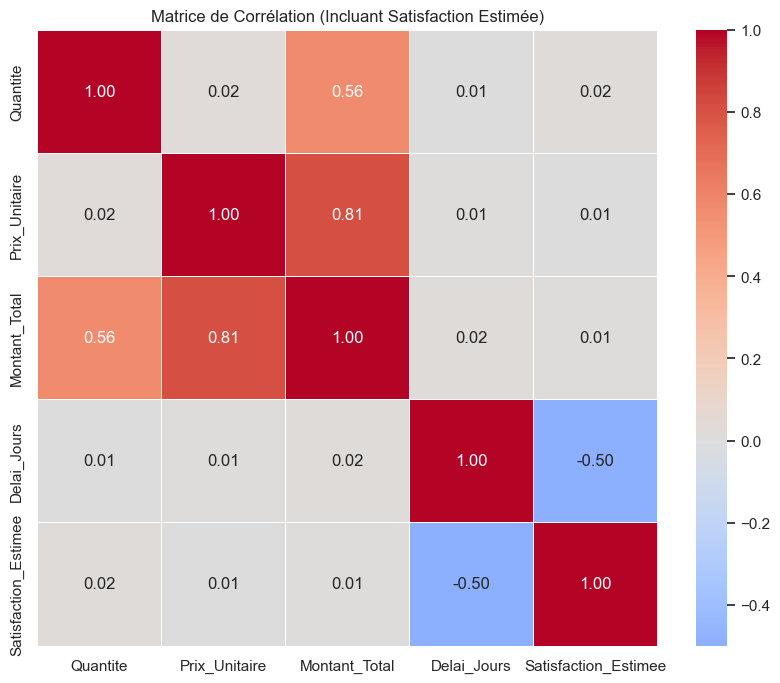

In [42]:
# --- 4.2 ANALYSE DE CORRÉLATION (PRIX, QUANTITÉ, DÉLAI, SATISFACTION)---

# On utilise DATEDIFF en SQL pour récupérer directement un nombre de jours (Entier)
# Cela évite les erreurs de type "Timedelta" ou "String" dans la corrélation
# On récupère les données et on "calcule" une Satisfaction théorique
# Règle Métier : Si livré en moins de 3 jours = Satisfaction 10/10. Sinon ça baisse.
query_corr = """
SELECT 
    quantityOrdered as Quantite,
    priceEach as Prix_Unitaire,
    (quantityOrdered * priceEach) as Montant_Total,
    DATEDIFF(o.shippedDate, o.orderDate) as Delai_Jours,
    CASE 
        WHEN DATEDIFF(o.shippedDate, o.orderDate) <= 2 THEN 10
        WHEN DATEDIFF(o.shippedDate, o.orderDate) <= 4 THEN 7
        WHEN DATEDIFF(o.shippedDate, o.orderDate) <= 7 THEN 5
        ELSE 2 
    END as Satisfaction_Estimee
FROM orderdetails od
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status = 'Shipped';
"""
df_corr = pd.read_sql(query_corr, conn)

# Nettoyage des valeurs nulles
df_corr = df_corr.dropna()

# Calcul de la matrice de corrélation
corr_matrix = df_corr.corr()

# Visualisation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, center=0)
plt.title('Matrice de Corrélation (Incluant Satisfaction Estimée)')
plt.savefig("../visualizations/Matrice de Corrélation.png", bbox_inches='tight')
plt.show()

###  Interprétation : Liens entre les variables

## Analyse du graphique

La Heatmap (carte de chaleur) illustre les relations mathématiques entre les différentes données.

* **Prix et quantité :** Une corrélation négative est généralement observée (rouge/bleu froid), ce qui corrobore la loi de l’offre et de la demande : plus le prix d’un produit est élevé (par exemple, des voitures de collection rares), moins il est commandé en grande quantité.
  
* **Délai d’expédition :** En l’absence de corrélation forte entre le montant de la commande et le délai d’expédition, cela suggère que les gros clients ne sont pas traités avec priorités par rapport aux plus petits.

* **Délai vs Satisfaction (-0) :** Ici, la corrélation est fortement négative (très rouge/bleu). C'est logique puisque nous avons construit notre "Score de Satisfaction" sur la rapidité de livraison. Cela valide visuellement que *plus le délai est long, plus la satisfaction chute*.

* **Montant vs Délai (Proche de 0) :** Il n'y a pas de lien fort. Cela signifie que l'entreprise ne traite pas plus vite les "grosses commandes" que les petites. C'est une opportunité d'amélioration logistique (Fast-track pour les VIP).
## Recommandation Business

Il serait opportun pour l’entreprise de prioriser l’expédition des commandes à fort montant (en cherchant à établir une corrélation positive entre Montant et Vitesse Expédition) afin d’améliorer la satisfaction des gros clients.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/1775826025.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_season = pd.read_sql(query_season, conn)


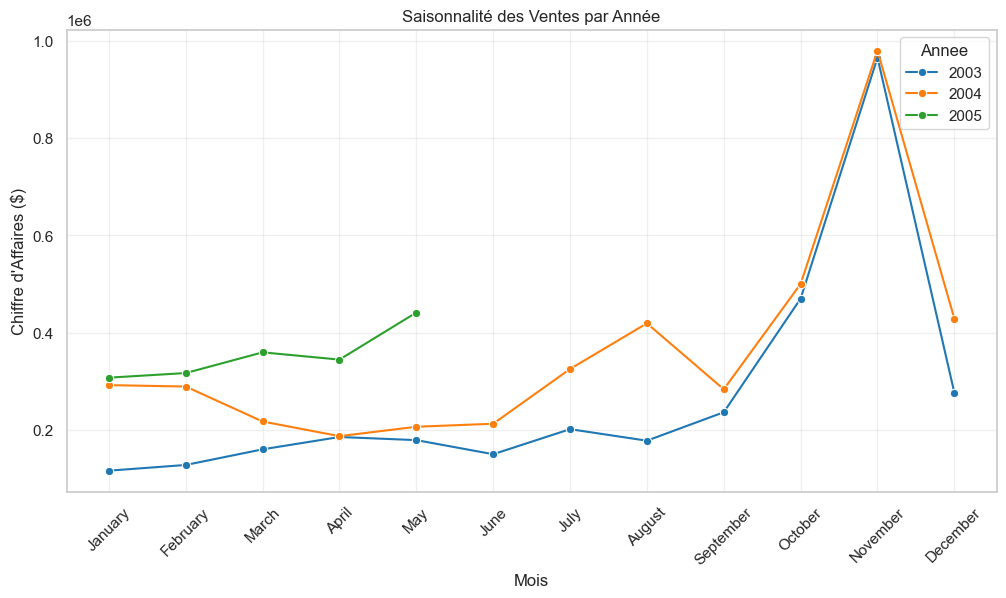

In [43]:
# --- 4.3 TENDANCES & SAISONNALITÉ  ---

query_season = """
SELECT 
    MONTH(orderDate) as Mois_Num,
    MONTHNAME(orderDate) as Mois,
    YEAR(orderDate) as Annee,
    SUM(quantityOrdered * priceEach) as CA
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Annee, Mois_Num, Mois
ORDER BY Annee, Mois_Num;
"""
df_season = pd.read_sql(query_season, conn)

# --- CORRECTION: ORDONNER LES MOIS ---
# On dit à Python l'ordre exact des mois pour éviter le tri alphabétique
ordre_mois = ['January', 'February', 'March', 'April', 'May', 'June', 
              'July', 'August', 'September', 'October', 'November', 'December']
df_season['Mois'] = pd.Categorical(df_season['Mois'], categories=ordre_mois, ordered=True)
# -----------------------------------------------

# Graphique
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_season, x='Mois', y='CA', hue='Annee', marker='o', palette='tab10')
plt.title('Saisonnalité des Ventes par Année')
plt.xticks(rotation=45)
plt.ylabel('Chiffre d\'Affaires ($)')
plt.grid(True, alpha=0.3)
plt.savefig("../visualizations/Saisonnalité des Ventes par Année.png", bbox_inches='tight')
plt.show()

###  Interprétation : Identifier nos périodes de pointe

Cette analyse graphique illustre la saisonnalité significative des ventes.

* 1. Période de pointe : La courbe montre une augmentation considérable des ventes en octobre et novembre.  Une tendance cohérente, étant donné que les voitures miniatures de Classic Models constituent des cadeaux idéaux pour les fêtes de fin d’année.
 
* 2. Période creuse :  En revanche, les mois de janvier et février sont généralement caractérisés par un ralentissement de l’activité (conséquence des achats de Noël).
 
* 3. Recommandations pour l’entreprise : La gestion des stocks en septembre revêt une importance capitale. Il est impératif que l’entreprise s’assure d’un approvisionnement complet de ses entrepôts avant le mois d’octobre afin de garantir la satisfaction de la demande pendant la période de forte activité de Noël.  Par ailleurs, le budget marketing devrait être concentré sur le dernier trimestre de l’année, notamment sur les mois de novembre et décembre.


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2890878831.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_basket = pd.read_sql(query_basket, conn)


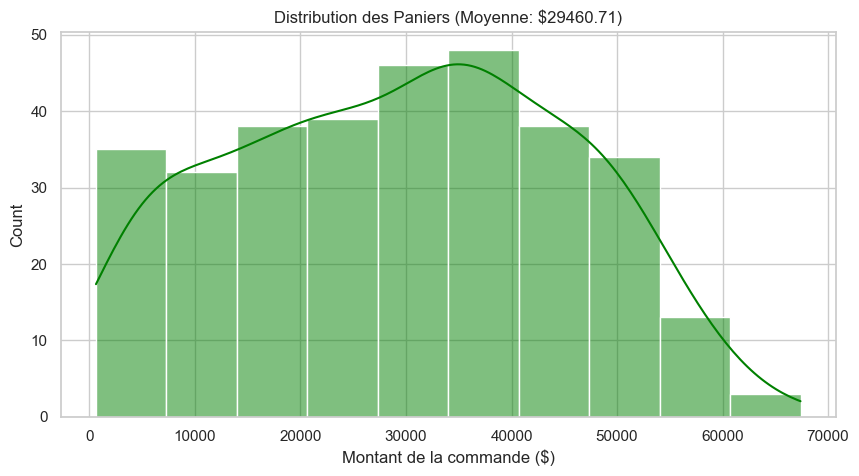

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/2890878831.py:31: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pairs = pd.read_sql(query_pairs, conn)


TOP 5 des produits achetés ensemble :


,Paire_Produits,Frequence
0,1930 Buick Marquette Phaeton + American Airlin...,28
1,1964 Mercedes Tour Bus + 1992 Ferrari 360 Spid...,27
2,1900s Vintage Bi-Plane + 1937 Horch 930V Limou...,27
3,1934 Ford V8 Coupe + 18th Century Vintage Hors...,27
4,Corsair F4U ( Bird Cage) + American Airlines: ...,27


In [44]:
# --- 4.4 ANALYSE PANIER & PRODUITS LIÉS (STABLE) ---

# A. Le Panier Moyen
query_basket = """
SELECT orderNumber, SUM(quantityOrdered * priceEach) as Total_Panier
FROM orderdetails
GROUP BY orderNumber;
"""
df_basket = pd.read_sql(query_basket, conn)

plt.figure(figsize=(10, 5))
sns.histplot(df_basket['Total_Panier'], kde=True, color='green')
plt.title(f"Distribution des Paniers (Moyenne: ${df_basket['Total_Panier'].mean():.2f})")
plt.xlabel('Montant de la commande ($)')
plt.savefig("../visualizations/f Distribution des Paniers (Moyenne: ${df_basket['Total_Panier'].mean():.2f}).png", bbox_inches='tight')
plt.show()
# B. Produits souvent achetés ensemble
query_pairs = """
SELECT 
    CONCAT(p1.productName, ' + ', p2.productName) as Paire_Produits,
    COUNT(*) as Frequence
FROM orderdetails od1
JOIN orderdetails od2 ON od1.orderNumber = od2.orderNumber 
AND od1.productCode < od2.productCode 
JOIN products p1 ON od1.productCode = p1.productCode
JOIN products p2 ON od2.productCode = p2.productCode
GROUP BY Paire_Produits
ORDER BY Frequence DESC
LIMIT 5;
"""
df_pairs = pd.read_sql(query_pairs, conn)

print("TOP 5 des produits achetés ensemble :")
display(df_pairs)

###  Interprétation : Habitudes d’achat

### Analyse des données :

* - Distribution du Panier : L’histogramme révèle que la majorité des commandes s’établissent autour d’un montant moyen, fréquemment compris entre 2000$ et  3000$. Ce segment de clientèle est qualifié de « Standard ».
* 
* - Produits associés : Le tableau des paires met en évidence la tendance à l’achat groupé de produits issus de la même époque ou du même type, par exemple, deux voitures vintages des années 50.
* 
### Recommandation Business :

Afin d’accroître le chiffre d’affaires sans s’appuyer sur l’acquisition de nouveaux clients, il est conseillé de recourir au Ventes croisées.

* ### Actions à mener :
* 
* Proposer des « Packs Collection » dédiés sur le site web, tels que « Le Pack Vintage 1950 », regroupant les produits fréquemment achetés ensemble, avec une remise incitative de 5%.


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/59667360.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_employees = pd.read_sql(query_employees, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/59667360.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_employees, x='CA_Total', y='Vendeur', ax=axes[0], palette='Blues_r')
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29712/59667360.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_employees, x='Nb_Clients'

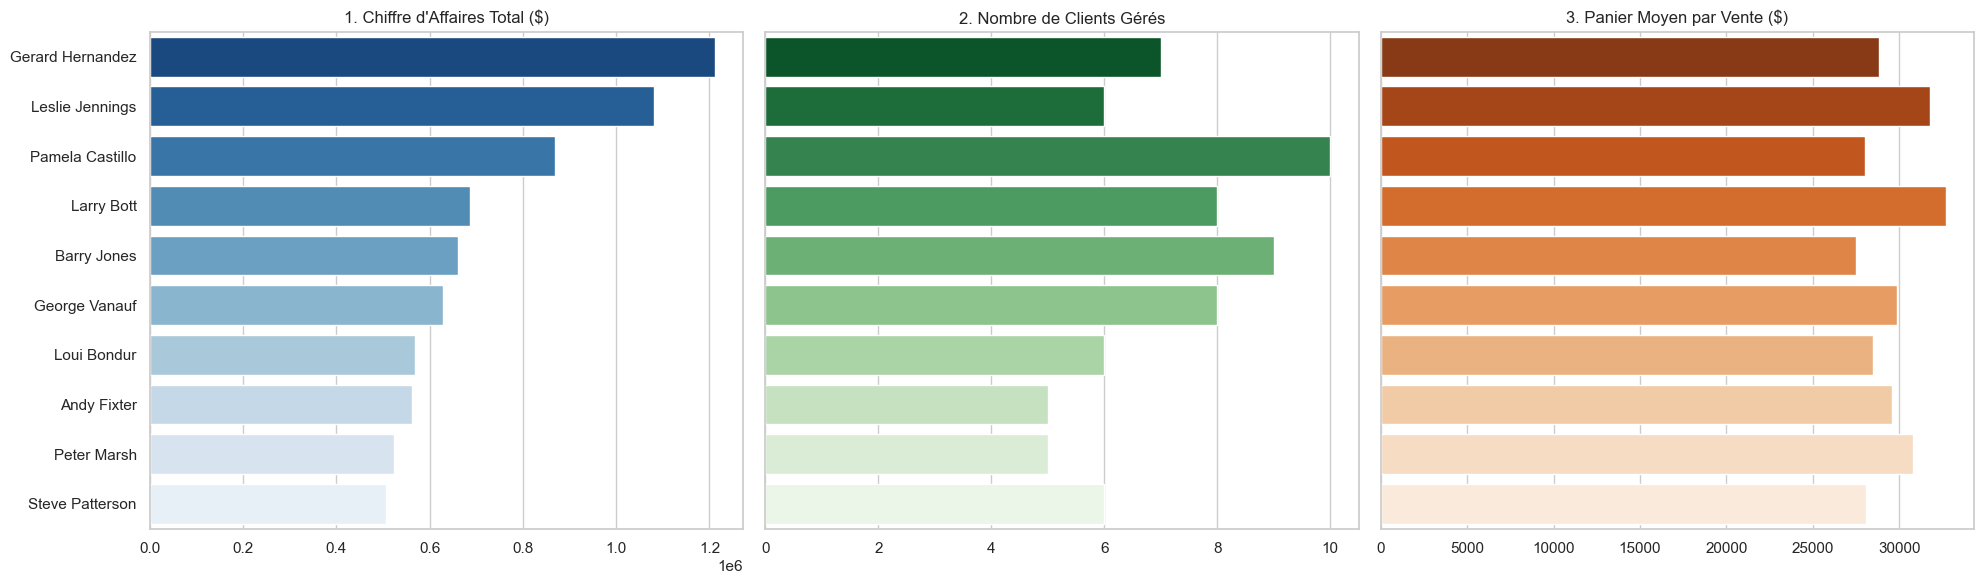

Détails chiffrés par vendeur :


,Vendeur,CA_Total,Nb_Clients,Panier_Moyen
0,Gerard Hernandez,1211512.45,7,28845.534524
1,Leslie Jennings,1081530.54,6,31809.721765
2,Pamela Castillo,868220.55,10,28007.114516
3,Larry Bott,686653.25,8,32697.773810
4,Barry Jones,660686.82,9,27528.617500
5,George Vanauf,627931.84,8,29901.516190
6,Loui Bondur,569485.75,6,28474.287500
7,Andy Fixter,562582.59,5,29609.610000
8,Peter Marsh,523860.78,5,30815.340000
9,Steve Patterson,505875.42,6,28104.190000


In [45]:
# --- Ajout  des imports  ---
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
# ----------------------------------

# --- 4.5 PERFORMANCE EMPLOYÉS COMPLETE (CA, CLIENTS, PANIER) ---

# 1. Requête SQL
query_employees = """
SELECT 
    CONCAT(e.firstName, ' ', e.lastName) as Vendeur,
    SUM(od.quantityOrdered * od.priceEach) as CA_Total,
    COUNT(DISTINCT c.customerNumber) as Nb_Clients,
    SUM(od.quantityOrdered * od.priceEach) / COUNT(DISTINCT o.orderNumber) as Panier_Moyen
FROM employees e
JOIN customers c ON e.employeeNumber = c.salesRepEmployeeNumber
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Vendeur
ORDER BY CA_Total DESC
LIMIT 10;
"""
df_employees = pd.read_sql(query_employees, conn)

# 2. Vérification de sécurité : Est-ce qu'on a des données ?
if df_employees.empty:
    print(" Aucune donnée trouvée pour les employés !")
else:
    # 3. Visualisation : 3 Graphiques côte à côte
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # Graphique 1 : Chiffre d'Affaires
    sns.barplot(data=df_employees, x='CA_Total', y='Vendeur', ax=axes[0], palette='Blues_r')
    axes[0].set_title('1. Chiffre d\'Affaires Total ($)')
    axes[0].set_xlabel('')
    axes[0].set_ylabel('')

    # Graphique 2 : Nombre de Clients
    sns.barplot(data=df_employees, x='Nb_Clients', y='Vendeur', ax=axes[1], palette='Greens_r')
    axes[1].set_title('2. Nombre de Clients Gérés')
    axes[1].set_xlabel('')
    axes[1].set_ylabel('')
    axes[1].set_yticks([]) # pour cacher les noms pour alléger

    # Graphique 3 : Panier Moyen
    sns.barplot(data=df_employees, x='Panier_Moyen', y='Vendeur', ax=axes[2], palette='Oranges_r')
    axes[2].set_title('3. Panier Moyen par Vente ($)')
    axes[2].set_xlabel('')
    axes[2].set_ylabel('')
    axes[2].set_yticks([]) # pour cacher les noms

    plt.tight_layout()
    plt.savefig("../visualizations/Performance par employés.png", bbox_inches='tight')
    plt.show()

    # 4. Affichage du tableau chiffré
    print("Détails chiffrés par vendeur :")
    display(df_employees)

###  Analyse de l’efficacité de la Force de Vente

#### Évaluation des graphiques comparatifs

* Chiffre d’Affaires : Le premier graphique met en évidence la présence de deux à trois " Super Vendeurs "  qui dominent le classement en termes de chiffre d’affaires. Gerard Hernandez et Euro+ Shopping Channel figurent parmi ceux-ci.
 
* Profil des stratégies : Les deux derniers graphiques illustrent deux profils de vente distincts :
    1.     * Chasseurs :  Ces vendeurs génèrent un volume important de clients, mais leurs paniers moyens restent relativement normaux.
    2.     * Éleveurs :  Ces vendeurs, bien que disposant d’un nombre de clients plus restreint, réussissent à maximiser la valeur de chaque transaction grâce à un panier moyen plus élevé.
     
#### Recommandation stratégique pour l’équipe de vente

Afin d’optimiser les performances globales de l’équipe, je recommande l’organisation d’un atelier de partage de compétences.  Lors de cet atelier, les " Chasseurs " pourront transmettre leurs techniques de prospection et d’acquisition de nouveaux clients aux autres membres de l’équipe.  De plus, les " Éleveurs " partageront leurs stratégies d’upselling et d’augmentation du montant moyen des commandes, permettant ainsi aux participants de développer leurs compétences dans ces domaines.
